In [1]:
import torch
import tifffile
import numpy as np
import os
from tqdm import tqdm
from skimage import exposure
from micro_sam.automatic_segmentation import get_predictor_and_segmenter, automatic_instance_segmentation

2026-01-19 11:10:58.584506: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1768817458.647250   90747 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1768817458.668411   90747 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [6]:
# ============================
# 1. CONFIGURATION
# ============================
MODEL_TYPE = "vit_b_lm"
CHECKPOINT_PATH = r"/work/scratch/rawat/microsam_training_output/checkpoints/vit_b_lm_patch1024_001percentile/best.pt"
INPUT_IMAGE_PATH = r"/home/students/rawat/czi_output/processed_images/PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit.ome.tif"
OUTPUT_MASK_PATH = r"/home/students/rawat/czi_output/Annotations/Processed_labels/predicted/PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit_label_vit_b_lm_patch_1024_001percentile.tif"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Using device: {DEVICE}")
print(f"Using model: {MODEL_TYPE} with checkpoint: {CHECKPOINT_PATH}")
print(f"Input image: {INPUT_IMAGE_PATH}")

Using device: cuda
Using model: vit_b_lm with checkpoint: /work/scratch/rawat/microsam_training_output/checkpoints/vit_b_lm_patch1024_001percentile/best.pt
Input image: /home/students/rawat/czi_output/processed_images/PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit.ome.tif


In [7]:
raw_data = tifffile.imread(INPUT_IMAGE_PATH)
print(f"Original shape: {raw_data.shape}")

# Extract Channel 0 based on axis order
if raw_data.ndim == 4:
    if raw_data.shape[0] <= 4:  # (C, Z, Y, X)
        raw_data = np.transpose(raw_data, (1, 2, 3, 0))
    elif raw_data.shape[1] <= 4:  # (Z, C, Y, X)
        raw_data = np.transpose(raw_data, (0, 2, 3, 1))
elif raw_data.ndim == 3:
        # Assume (Z, Y, X) if 3D, add dummy channel dim -> (Z, Y, X, 1)
        raw_data = raw_data[..., np.newaxis]

print(f"Processed shape (Z, Y, X): {raw_data.shape}")

print(f"The data type is {raw_data.dtype}, normalizing to uint8.")
# Calculate percentiles on the entire 3D volume at once
low, high = np.percentile(raw_data, (0.00001, 99.9999))
print(f"Percentile values: low={low}, high={high}")

if high > low:
    # Normalize to 0-1 as float32
    raw_data = (raw_data.astype(np.float32) - low) / (high - low)
    raw_data = np.clip(raw_data, 0, 1)
else:
    # Flat image fallback
    raw_data = np.zeros_like(raw_data, dtype=np.float32)

Z, Y, X, C = raw_data.shape
raw_data_rgb = np.zeros((Z, Y, X, 3), dtype=raw_data.dtype)

raw_data_rgb[..., :min(C, 2)] = raw_data[..., :min(C, 2)]
print(f"Final RGB shape: {raw_data_rgb.shape}")

Original shape: (2, 75, 1101, 1101)
Processed shape (Z, Y, X): (75, 1101, 1101, 2)
The data type is uint16, normalizing to uint8.
Percentile values: low=33.0, high=35273.18895703554
Final RGB shape: (75, 1101, 1101, 3)


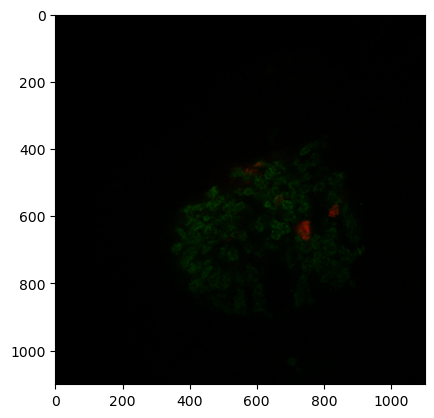

In [8]:
## plot the raw_data_rgb
import matplotlib.pyplot as plt
plt.imshow(raw_data_rgb[41])  # Display full RGB with both red and green channels
plt.show()

In [9]:
# ============================
# 3. INITIALIZE MODEL
# ============================
print("Loading model...")
# We load the model ONCE, then reuse it for every slice
predictor, segmenter = get_predictor_and_segmenter(
    model_type=MODEL_TYPE,
    checkpoint=CHECKPOINT_PATH,
    device=DEVICE,
)

# ============================
# 4. RUN INFERENCE LOOP (One by One)
# ============================
prediction_stack = []

print(f"Starting Slice-by-Slice Inference on {raw_data_rgb.shape[0]} slices...")

# Tqdm gives you a progress bar
for z in tqdm(range(raw_data_rgb.shape[0]), desc="Processing Slices"):
    
    # A. Get single slice
    img_slice = raw_data_rgb[z] # (Y, X,Z)

    # E. Predict (ndim=2 because it's just one image)
    # We pass the pre-loaded 'predictor' so it's fast
    pred_2d = automatic_instance_segmentation(
        predictor=predictor,
        segmenter=segmenter,
        input_path=img_slice,
        ndim=2, # <--- 2D MODE
        # tile_shape=(512, 512), # Optional: tiling within the 2D slice
        halo=(64, 64)
    )
    
    prediction_stack.append(pred_2d)

# ============================
# 5. SAVE RESULT
# ============================
print("Stacking results...")
final_stack = np.array(prediction_stack)

print(f"Saving 3D result to: {OUTPUT_MASK_PATH}")
tifffile.imwrite(OUTPUT_MASK_PATH, final_stack)
print("Done!")

Loading model...
Starting Slice-by-Slice Inference on 75 slices...


Processing Slices: 100%|██████████| 75/75 [00:37<00:00,  2.01it/s]


Stacking results...
Saving 3D result to: /home/students/rawat/czi_output/Annotations/Processed_labels/predicted/PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit_label_vit_b_lm_patch_1024_001percentile.tif
Done!
